In [1]:
import logging
import random
from sklearn.feature_selection import mutual_info_regression
import re
import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt
from sympy import simplify
from main import run_ga
import threading
SEED = 2
np.random.seed(SEED)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)

differential = False

def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    residuals = y_true - y_pred
    ss_res = float(np.sum(residuals ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot else float("nan")
    rmse = float(np.sqrt(np.mean(residuals ** 2)))
    return r2, rmse

def simplify_with_timeout(expr, timeout_seconds=5):
    """
    Attempt to simplify with a timeout using threading.
    Returns simplified expression or original if timeout occurs.
    """
    result = [None]
    exception = [None]
    
    def target():
        try:
            result[0] = simplify(expr)
        except Exception as e:
            exception[0] = e
    
    thread = threading.Thread(target=target, daemon=True)
    thread.start()
    thread.join(timeout=timeout_seconds)
    
    if thread.is_alive():
        print(f"Warning: Simplification timed out after {timeout_seconds}s, using unsimplified expression")
        return expr
    
    if exception[0]:
        raise exception[0]
    
    return result[0]


/home/sandy/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Using device: cpu


/home/sandy/.local/lib/python3.10/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
df = pd.read_csv("monsoon.csv")

df_long = df.melt(
    id_vars=["PARAMETER", "YEAR"],
    var_name="MONTH",
    value_name="VALUE"
)

df_pivot = df_long.pivot_table(
    index=["YEAR", "MONTH"],
    columns="PARAMETER",
    values="VALUE"
).reset_index()

month_map = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5,
             "JUN": 6, "JUL": 7, "AUG": 8, "SEP": 9,
             "OCT": 10, "NOV": 11, "DEC": 12}

df_pivot["MONTH_NUM"] = df_pivot["MONTH"].map(month_map)

df_pivot["DATE"] = pd.to_datetime(
    df_pivot["YEAR"].astype(str) + "-" + df_pivot["MONTH_NUM"].astype(str)
)
df_pivot.set_index("DATE", inplace=True)

df_final = df_pivot.drop(columns=["YEAR", "MONTH", "MONTH_NUM"])

def sanitize(name: str) -> str:
    s = name.strip()
    s = re.sub(r"\W+", "_", s)
    if s and s[0].isdigit():
        s = f"v_{s}"
    s = s[:2]
    return s

col_map = {c: sanitize(c) for c in df_final.columns}
df_final.rename(columns=col_map, inplace=True)

df_final = (
    df_final.apply(pd.to_numeric, errors="coerce")
    .replace([pd.NA, float("inf"), -float("inf")], pd.NA)
    .dropna()
)
if differential:
    for column in df_final.columns:
        df_final[f"d{column}"] = np.gradient(df_final[column].to_numpy(dtype=float))
%matplotlib inline


Mutual information for target 'Pr':


,MI
So,0.330292
Sp,0.245303
Te,0.080265


Mutual information for target 'So':


,MI
Te,0.813724
Sp,0.501782
Pr,0.334041


Mutual information for target 'Sp':


,MI
So,0.516858
Te,0.382066
Pr,0.241949


Mutual information for target 'Te':


,MI
So,0.857332
Sp,0.380318
Pr,0.081176


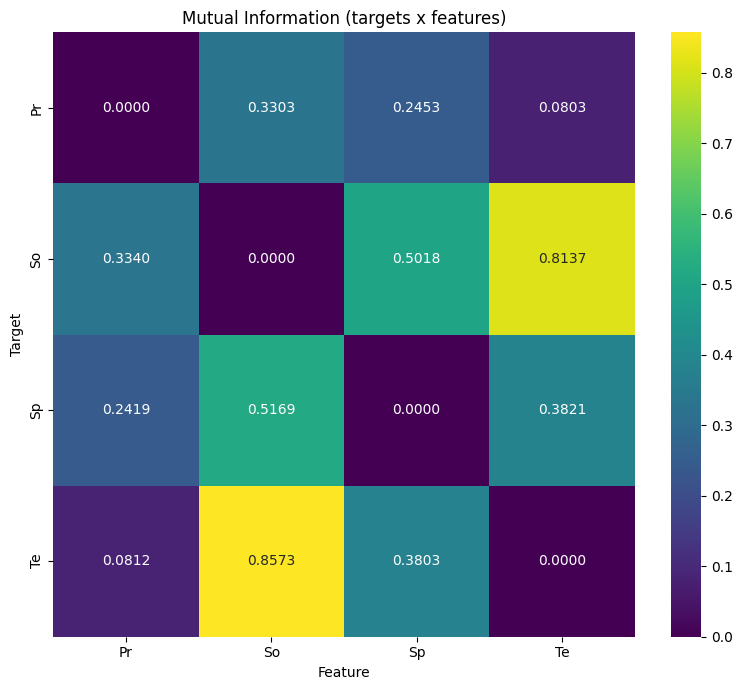

In [3]:
# compute MI with every column as target
targets = list(df_final.columns)
if len(df_final.columns) <= 1:
    print("Not enough columns to compute mutual information (need at least 1 feature and 1 target).")
else:
    mi_results = {}
    for t in df_final.columns:
        # use all other columns as features for this target
        feature_df = df_final.drop(columns=[t])
        X = feature_df.to_numpy(dtype=float)
        feature_names = feature_df.columns.tolist()

        y = df_final[t].to_numpy(dtype=float)
        mi = mutual_info_regression(X, y, discrete_features=False, random_state=SEED)
        mi_series = pd.Series(mi, index=feature_names).sort_values(ascending=False)
        mi_results[t] = mi_series
        print(f"Mutual information for target '{t}':")
        display(mi_series.to_frame(name="MI"))

    # combined table (targets x features)
    mi_df = pd.DataFrame(mi_results).T.fillna(0)
    plt.figure(figsize=(max(8, 0.8 * mi_df.shape[1]), 3 + mi_df.shape[0]))
    sns.heatmap(mi_df, annot=True, fmt=".4f", cmap="viridis")
    plt.title("Mutual Information (targets x features)")
    plt.xlabel("Feature")
    plt.ylabel("Target")
    plt.tight_layout()
    plt.show()


Correlation matrix: PARAMETER        Pr        So        Sp        Te
PARAMETER                                        
Pr         1.000000  0.482160  0.585487 -0.421531
So         0.482160  1.000000  0.788807 -0.789661
Sp         0.585487  0.788807  1.000000 -0.709625
Te        -0.421531 -0.789661 -0.709625  1.000000


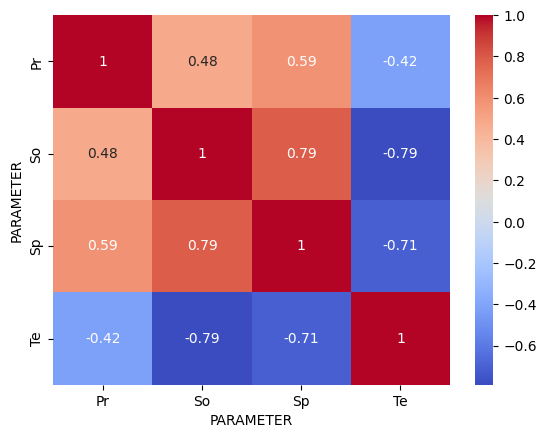

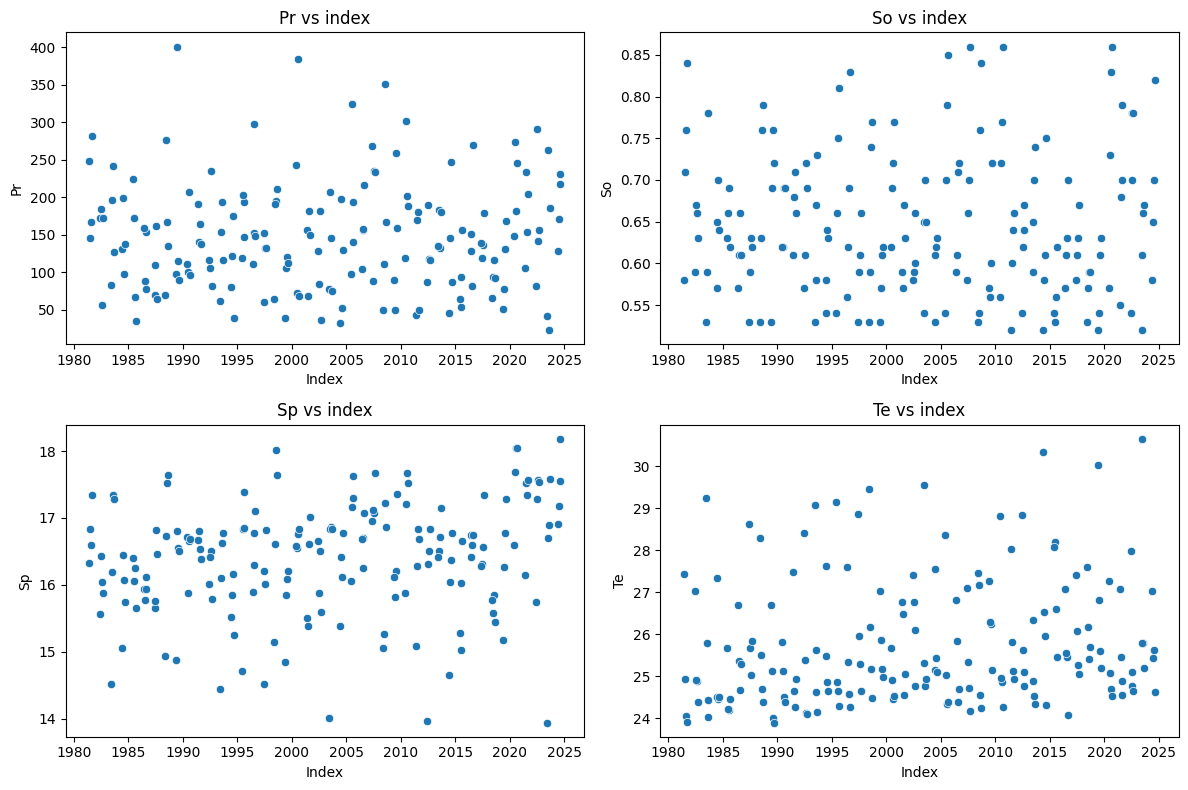

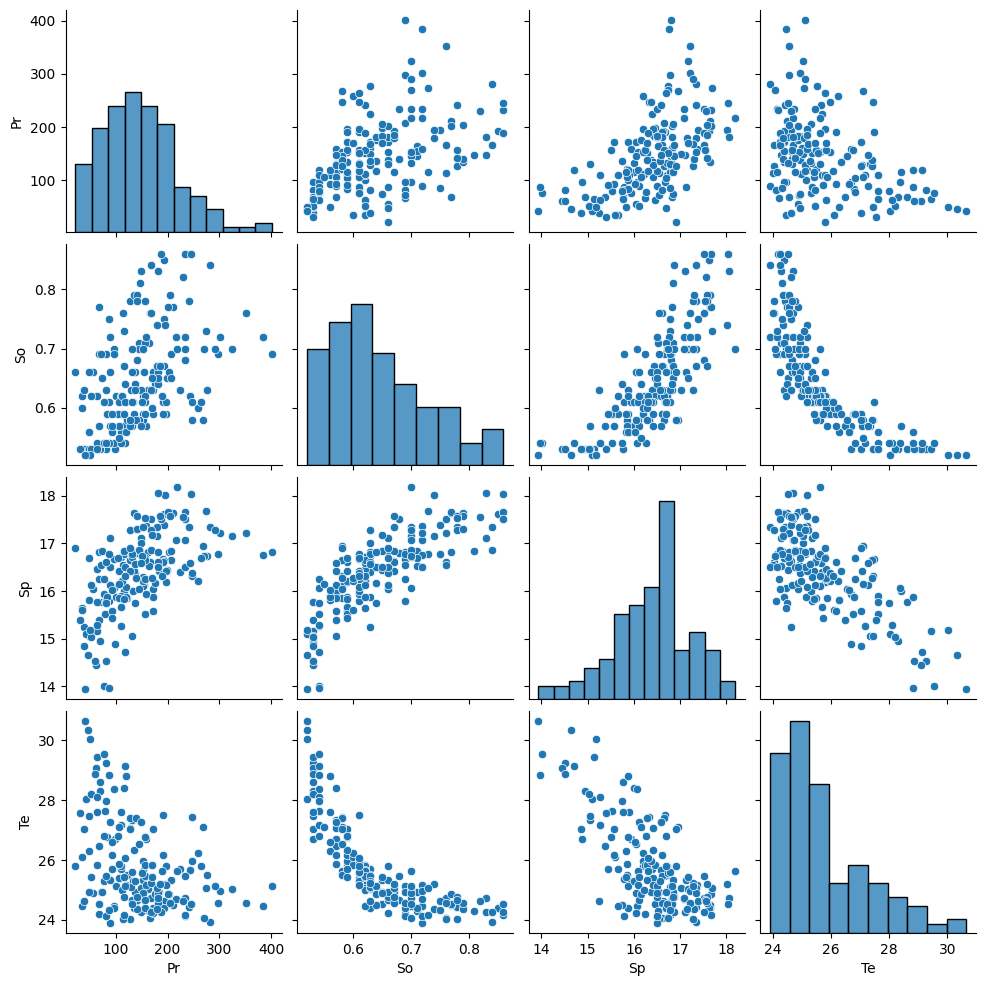

In [4]:
print("Correlation matrix:", df_final.corr())
sns.heatmap(data=df_final.corr(), annot=True, cmap="coolwarm")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, df_final.columns):
    sns.scatterplot(x=df_final.index, y=df_final[col], ax=ax)
    ax.set_title(f"{col} vs index")
    ax.set_xlabel("Index")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

sns.pairplot(df_final)
plt.show()


In [5]:
target = "Pr"
feature_cols = [c for c in df_final.columns if c != target]
print(df_final.head())

X = df_final[feature_cols].to_numpy(dtype=float)
y = df_final[target].to_numpy(dtype=float)

unary_funcs = {
        'sin': (np.sin, sp.sin),
        'cos': (np.cos, sp.cos),
        'tan': (np.tan, sp.tan),
        'exp': (np.exp, sp.exp),
        'sqrt': (np.sqrt, sp.sqrt)
    }

PARAMETER       Pr    So     Sp     Te
DATE                                  
1981-08-01  167.08  0.76  16.60  24.05
1981-07-01  145.41  0.71  16.84  24.93
1981-06-01  247.83  0.58  16.32  27.44
1981-09-01  281.74  0.84  17.34  23.92
1982-08-01   55.79  0.66  16.04  24.88


In [ ]:
print(f"Running genetic algorithm for '{target}' against {feature_cols}")
best, best_score = run_ga(
    X,
    y,
    pop_size=1500,
    gens=300,
    max_init_depth=4,
    max_depth=10,
    crossover_rate=0.85,
    mutation_rate=0.2,
    tournament_k=5,
    elitism=15,
    var_names=feature_cols,
    unary_funcs=unary_funcs,
    use_learned_crossover=True,
    selector_lr=0.0005,
    use_transformer=False,
    transformer_heads=8,
    transformer_layers=4,
    mlp_layers=10,
    mlp_hidden_dim=128,
    mlp_activation="gelu",
    mlp_dropout=0.1,
    stopping_metric="r2",
    stopping_threshold=None,
    # NEW: Additional customization options
    complexity_coef=1e-5,
    inclusion_coef=0.5,
    prob_const=0.35,
    const_range=(-3, 3),
    point_mutation_prob=0.1,
    selector_update_freq=3,
    temperature=0.7,
    critic_weight=0.6,
    entropy_weight=0.02,
    verbose=True,
    print_freq=10,
    seed=2,
)

if best is None:
    raise RuntimeError("Genetic algorithm did not return a valid expression.")

sym_expr = simplify_with_timeout(best.to_sympy(), timeout_seconds=30)
feature_values = {name: df_final[name].to_numpy(dtype=float) for name in feature_cols}
y_pred = best.evaluate(feature_values)
r2, rmse = regression_metrics(y, y_pred)

# compute MAPE and SMAPE (robust to zeros)
eps = 1e-8
mape = float(np.mean(np.abs((y - y_pred) / np.where(np.abs(y) < eps, eps, y)))) * 100.0
smape = float(
    np.mean(
        2.0 * np.abs(y - y_pred)
        / np.where((np.abs(y) + np.abs(y_pred)) < eps, eps, (np.abs(y) + np.abs(y_pred)))
    )
) * 100.0

print(f"Best score (MSE + penalty): {best_score:.6f}")
print(f"Sympy expression: {sym_expr}")
print(f"R2: {r2:.4f}, RMSE: {rmse:.4f}, MAPE: {mape:.4f}%, SMAPE: {smape:.4f}%")

# plotting with error bars / uncertainty band
residuals = y - y_pred
# use standard deviation of residuals as uncertainty (1σ)

plt.figure(figsize=(10, 5))
plt.scatter(df_final.index, y, label="Actual", alpha=0.7, zorder=5)
plt.plot(df_final.index, y_pred, label="Predicted", color="red", zorder=6)

# shaded ±1σ, ±2σ, ±3σ bands around prediction
sigma = float(np.std(residuals))
upper1 = y_pred + sigma
lower1 = y_pred - sigma
upper2 = y_pred + 2 * sigma
lower2 = y_pred - 2 * sigma
upper3 = y_pred + 3 * sigma
lower3 = y_pred - 3 * sigma

# widest (3σ) first so it sits behind narrower bands
plt.fill_between(df_final.index, lower3, upper3, color='orange', alpha=0.08, label=f"±3σ (σ={sigma:.3f})", zorder=1)
plt.fill_between(df_final.index, lower2, upper2, color='orange', alpha=0.12, label=f"±2σ (σ={sigma:.3f})", zorder=2)
plt.fill_between(df_final.index, lower1, upper1, color='red', alpha=0.18, label=f"±1σ (σ={sigma:.3f})", zorder=3)

plt.errorbar(df_final.index, y_pred, yerr=sigma, fmt='none', ecolor='red', alpha=0.3, capsize=2, zorder=4)

plt.title(target)
plt.xlabel("Date")
plt.ylabel(str(sym_expr))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"predict_{target}.pdf", bbox_inches='tight')
plt.show()


Running genetic algorithm for 'Pr' against ['So', 'Sp', 'Te']
Using learned subtree crossover with MLP (10 layers, 128 hidden, gelu activation, 0.1 dropout, A2C (with critic))


/media/sandy/Stuff/Programming/rllxo/main.py:165: RuntimeWarning: invalid value encountered in sqrt
  return f(self.child.evaluate(inputs))


Gen   1 best MSE+penalty: 6231.92 R²: -0.222006 expr: exp((exp(sqrt(1.928)) + So))


/media/sandy/Stuff/Programming/rllxo/main.py:165: RuntimeWarning: overflow encountered in exp
  return f(self.child.evaluate(inputs))
/media/sandy/Stuff/Programming/rllxo/main.py:931: RuntimeWarning: overflow encountered in square
  mse = float(np.mean((y - y_pred)**2))
/media/sandy/Stuff/Programming/rllxo/main.py:165: RuntimeWarning: invalid value encountered in cos
  return f(self.child.evaluate(inputs))
/home/sandy/.local/lib/python3.10/site-packages/numpy/_core/_methods.py:135: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/media/sandy/Stuff/Programming/rllxo/main.py:165: RuntimeWarning: invalid value encountered in sin
  return f(self.child.evaluate(inputs))
/media/sandy/Stuff/Programming/rllxo/main.py:165: RuntimeWarning: invalid value encountered in tan
  return f(self.child.evaluate(inputs))


Gen  10 best MSE+penalty: 3757.3 R²: 0.263317 expr: ((exp((exp(sqrt(1.928)) + So)) + -0.4617) * ((cos(tan(sin((2.203 / So)))) / sin(2.402)) - (0.5765 + -0.6299)))
Gen  20 best MSE+penalty: 3613.93 R²: 0.291434 expr: (exp(So) + (((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((cos(tan(sin((2.203 / So)))) / So) - ((So / (sin(cos(((sin(So) + (exp(So) + exp(So))) + So))) / (So * (So / (2.46 + exp(2.742)))))) * So))) / tan((So / So))))
Gen  30 best MSE+penalty: 3554.09 R²: 0.303170 expr: (exp(So) + (((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((cos(tan(sin((2.203 / So)))) / So) - ((So / ((-2.32 + ((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(sqrt(1.928)) + So)) + sqrt(exp(((tan(sqrt(tan(sin(2.387)))) - (2.704 * So)) + exp(((((So / (((So / ((-2.32 + sin(((exp((exp(sqrt(1.928)) + So)) + (1.928 + (exp(sqrt(So)) + So))) * ((cos(tan(sin((2.203 / So)))) / sin(2.402)) - (0.5765 + -0.6299))))) / ((((((2.533 - sin(1.031)) + 1.549) 

/media/sandy/Stuff/Programming/rllxo/main.py:192: RuntimeWarning: invalid value encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/media/sandy/Stuff/Programming/rllxo/main.py:192: RuntimeWarning: overflow encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/media/sandy/Stuff/Programming/rllxo/main.py:26: RuntimeWarning: overflow encountered in divide
  return a / (b + 1e-6)
/media/sandy/Stuff/Programming/rllxo/main.py:26: RuntimeWarning: invalid value encountered in divide
  return a / (b + 1e-6)


Gen  40 best MSE+penalty: 3441.74 R²: 0.325205 expr: (exp(So) + (((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((cos(tan(sin((2.203 / So)))) / So) - ((So / ((-2.32 + ((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(sqrt(1.928)) + So)) + sqrt(exp(((tan(sqrt(tan(sin(2.387)))) - (2.704 * So)) + exp(((((So / (((So / ((-2.32 + sin(((exp((exp(sqrt(1.928)) + So)) + (1.928 + (exp(sqrt(So)) + So))) * (((-1.694 / sqrt(tan(sin((So / So))))) / sin(2.402)) - (0.5765 + -0.6299))))) / ((((((2.533 - sin(1.031)) + 1.549) - sin((sqrt(So) - (sin((sin(-2.434) / 1.994)) / 2.381)))) + (((So - So) + sin(So)) + cos((tan(2.686) + sqrt(((So / -2.083) / -2.32)))))) + So) * (-0.208 / (sin(So) + exp(2.742)))))) * (((exp((exp(sqrt(1.928)) + So)) + (1.928 + ((((sqrt(exp(sqrt(So))) / sqrt(1.928)) * (exp(-0.208) + tan(sin((So / (So - exp(sqrt(((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742))))))))))))) - (-1.694 / sqrt(tan(sin(2.387

/media/sandy/Stuff/Programming/rllxo/main.py:192: RuntimeWarning: invalid value encountered in add
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))


Gen  50 best MSE+penalty: 3413.14 R²: 0.330618 expr: (exp(So) + (((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((cos(tan(sin((2.203 / So)))) / So) - ((So / ((-2.32 + ((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(sqrt(1.928)) + So)) + sqrt(exp(((tan(sqrt(tan(sin(2.387)))) - (2.704 * So)) + exp(((((So / (((So / ((-2.32 + sin(((exp((exp(sqrt(1.928)) + So)) + (1.928 + (exp(sqrt(So)) + So))) * ((cos(tan(sin((2.203 / exp(((((So / ((-2.32 + ((((So / (So / (So * (-0.208 / (sin((2.668 / cos(So))) + exp(2.742)))))) * So) / cos((So / ((exp((exp(sqrt(exp(sqrt(So)))) + So)) + (1.659 + So)) * ((cos(tan(sin((So - exp((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(sqrt(1.928)) + sin(2.402))) + sqrt(exp(((tan((sin(sqrt(So)) / So)) - (2.704 * So)) + exp(((((So / So) * So) - (-1.694 / sin(So))) / tan(1.873)))))))) - (-1.694 / sqrt(tan(sin((So / So)))))) / So)))))))) / sin(2.4

/media/sandy/Stuff/Programming/rllxo/main.py:192: RuntimeWarning: invalid value encountered in subtract
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))


Gen  60 best MSE+penalty: 3399.76 R²: 0.333243 expr: (exp(So) + (((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((cos(tan(sin((-2.171 / So)))) / So) - ((So / ((-2.32 + ((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(sqrt(1.928)) + So)) + sqrt(exp(((tan(sqrt(tan(sin(2.387)))) - (2.704 * So)) + exp(((((So / (((So / ((-2.32 + sin(((exp((exp(sqrt(1.928)) + So)) + (1.928 + (exp(sqrt(So)) + So))) * ((cos(tan(sin((2.203 / exp(((((So / ((-2.32 + ((((So / (So / (So * (-0.208 / (sin((2.668 / cos(So))) + exp(2.742)))))) * So) / cos((So / ((exp((exp(sqrt(exp((sqrt(exp(sqrt(exp((exp(sqrt(exp(sqrt(So)))) + (sin(2.533) + sin(cos((So / So))))))))) / sqrt(So))))) + So)) + (1.659 + So)) * ((cos(tan(sin(So))) / So) - ((So / ((-2.32 + ((1.928 / ((-1.694 + exp(2.742)) / ((exp((exp(sqrt(exp(sqrt(So)))) + So)) + So) * ((2.668 / cos(((((So / ((-2.32 + sin(So)) / ((1.921 + 1.451) * (-0.208 / (sin(So) + exp(2.742)))))) * (exp((exp(((((So / ((-2.32 

In [ ]:
print(f"In LaTeX format: {sp.latex(sym_expr)}")
replacements, reduced_exprs = sp.cse(sym_expr)
print("CSE replacements (LaTeX):")
for idx, (sym, expr) in enumerate(replacements, 1):
    print(f"$t_{{{idx}}}: {sp.latex(sym)} = {sp.latex(expr)}$")

print("CSE reduced expressions (LaTeX):")
for idx, expr in enumerate(reduced_exprs, 1):
    print(f"$e_{{{idx}}}: {sp.latex(expr)}$")

In LaTeX format: 2 So + \sqrt[4]{Pr + \tan{\left(\tan{\left(\cos{\left(Te - \cos{\left(\sqrt{Te + e^{\frac{- 0.960236414697144 \sqrt{2} \sqrt{Pr} - 12.8513428084787}{\tan{\left(\sqrt[4]{2} \sqrt[4]{Pr} + Pr - \cos{\left(\tan{\left(Te \right)} \right)} - 10.6214666565528 \right)} + 15.8323113245592}} - \cos{\left(\sqrt{Pr e^{\frac{Pr - \tan{\left(So \right)} - 36.474173969545 + \frac{\cos{\left(\frac{- So + \cos{\left(\cos{\left(\tan{\left(Te \right)} \right)} \right)} - 0.0987141713447987}{\sqrt{Pr} + 1.0 \cdot 10^{-12}} \right)}}{Pr + 1.0 \cdot 10^{-12}}}{Pr + 1.0 \cdot 10^{-12}}} + \tan{\left(\tan{\left(So \right)} \right)}} \right)}} \right)} \right)} \right)} \right)}} - \cos{\left(\cos{\left(\tan{\left(Te \right)} \right)} \right)} - \cos{\left(\tan{\left(So \right)} \right)} + 12.6021760220776 + \frac{\tan{\left(\tan{\left(So \right)} \right)}}{e^{\frac{Pr + \sqrt{e^{\frac{0.614498564670432 Pr - Te - e^{0.419760908899876 \tan{\left(e^{\tan{\left(So \right)}} \right)}} + \cos{\lef

In [ ]:
sym_expr


2*So + (Pr + tan(tan(cos(Te - cos(sqrt(Te + exp((-0.960236414697144*sqrt(2)*sqrt(Pr) - 12.8513428084787)/(tan(2**(1/4)*Pr**(1/4) + Pr - cos(tan(Te)) - 10.6214666565528) + 15.8323113245592)) - cos(sqrt(Pr*exp((Pr - tan(So) - 36.474173969545 + cos((-So + cos(cos(tan(Te))) - 0.0987141713447987)/(sqrt(Pr) + 1.0e-12))/(Pr + 1.0e-12))/(Pr + 1.0e-12)) + tan(tan(So))))))))))**(1/4) - cos(cos(tan(Te))) - cos(tan(So)) + 12.6021760220776 + tan(tan(So))/(exp((Pr + sqrt(exp((0.614498564670432*Pr - Te - exp(0.419760908899876*tan(exp(tan(So)))) + cos(tan(Te)) + cos(sqrt(tan(tan(So)))) - 34.7792893800599 + (tan(So) + 15.8323113245582)/(exp((-exp(exp((Pr + Te + sqrt(exp((sqrt(Pr) + Pr - 28.3454373933277)/(Te + 1.0e-12))) + tan(Te) + tan(tan(Te)) - 40.5774586420268)/(Pr + 1.0e-12))) + tan(Pr) + tan(So) + tan(sqrt(cos(tan(Te)) + 10.6214666565528)/(1.0e-12 - 0.967713790338045/(tan(2**(1/4)*Pr**(1/4) + 2*Pr + tan(So) + tan(-0.992273153781096*cos(Pr) + tan(So) + 41.5846942076517) - 24.1167852629406) + 15.83

In [ ]:
best.to_string()

'(((sqrt(sqrt((tan(tan(cos((Te - cos(sqrt(((exp(((-0.9602 * (sqrt((Pr + Pr)) + exp(2.594))) / (exp(2.762) + tan((Pr + (sqrt(sqrt((Pr + Pr))) - ((cos(tan(Te)) - 2.762) + exp(2.594)))))))) + Te) - cos(sqrt((tan(tan(So)) + (exp(((Pr + ((sqrt((exp(2.762) + cos((-1.718 / 2.509)))) - (((((exp(2.762) + tan(So)) - -2.699) + (exp(2.509) - 2.627)) - (cos((((cos(cos(tan(Te))) + cos(-1.67)) - So) / sqrt(Pr))) / Pr)) + exp(2.594))) - -1.035)) / Pr)) * Pr))))))))))) + Pr))) + exp(2.594)) - ((((((cos(cos(tan(Te))) + cos(-1.67)) - So) + cos(tan(So))) + cos(-1.67)) - So) + cos(cos(-1.779)))) + (tan(tan(So)) / exp(((Pr + (sqrt(exp(((Pr + (sqrt((exp(2.509) - 2.594)) - ((((Pr + (exp(2.594) - -1.035)) / 2.594) + (exp(2.762) + ((exp(2.762) + ((exp(tan(2.762)) + Te) - (((exp(2.762) + tan(So)) / exp(((tan(So) + (sqrt(exp(2.762)) - ((((exp(exp(((Pr + (sqrt(exp(((Pr + (sqrt(Pr) - ((exp(2.762) + cos(2.627)) + exp(2.594)))) / Te))) - (((((exp(2.762) + cos((2.509 - exp(2.509)))) - tan(tan(Te))) + (exp(2.509) - tan